# Analyse du détecteur ML, version 3 : l'effet de la règle « silence »

Ce notebook compare, pour **chaque modèle** (Isolation Forest, LOF, statistique), le détecteur **seul** et le même
détecteur **avec la règle silence** (`app/domaine/silence.py`), sur des incidents injectés dans du trafic réel :
flood, scan (refus), baisse de trafic, et pannes de 20, 30 et 60 s.

**À savoir** : la règle silence n'est pas *entraînée*. Les modèles apprennent toujours sur du trafic normal ; la règle
est une enveloppe qui s'ajoute autour d'eux et qui s'appuie sur la **moyenne de trafic apprise** pendant
l'entraînement (un service silencieux = 0 requête alors que sa moyenne apprise est d'au moins 3 requêtes par photo).
On entraîne donc chaque modèle une fois, et on le regarde avec et sans l'enveloppe.

Règle de lecture : **score < 0 = photo anormale** (1 photo = 10 s). Une alerte demande 3 photos anormales d'affilée.
Pour l'exécuter : `uv run jupyter lab` depuis `ML-Detector`. Données : `data/normal.csv`.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))

import config
from app.domaine.detecteur import AnomalyDetector, IncidentTracker
from app.domaine.evaluation import comparer
from app.domaine.silence import DetecteurAvecSilence, RegleSilence

plt.rcParams.update({"figure.figsize": (11, 3.6), "figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

CHEMIN_NORMAL = RACINE / "data" / "normal.csv"
SERVICE = "basecamp-shop"
FEATURE = f"{SERVICE}__req_count"
DENIED = f"{SERVICE}__denied_count"
NON_SUCCESS = f"{SERVICE}__non_success_count"
COLONNE_SCORE = f"score_{SERVICE}"
print("Règle silence :", "ACTIVE" if config.SILENCE_ACTIF else "désactivée dans config.py",
      f"| trafic habituel minimal : {config.SILENCE_TRAFIC_MIN} req/photo | intensité : {config.SILENCE_INTENSITE}")

Règle silence : ACTIVE | trafic habituel minimal : 3.0 req/photo | intensité : 12.0


## 1. Données et découpe

In [2]:
df = pd.read_csv(CHEMIN_NORMAL)
df["heure"] = pd.to_datetime(df["timestamp"], unit="s", utc=True)
mesures = [c for c in df.columns if "__" in c]
print(f"{len(df)} photos de 10 s = {len(df) * 10 / 60:.0f} min | requêtes : {int(df[FEATURE].sum())} "
      f"| refus : {int(df[DENIED].sum())} | photos à 0 requête : {int((df[FEATURE] == 0).sum())}")

# Partie active (moyenne glissante d'1 min > 4 requêtes), puis 75 % entraînement / 25 % test dans le temps.
actif = df.index[df[FEATURE].rolling(6, min_periods=1).mean() > 4]
active = df.loc[actif.min():actif.max()].reset_index(drop=True)
cols = ["timestamp", *mesures]
coupure = int(len(active) * 0.75)
entrainement = active.loc[:coupure - 1, cols].reset_index(drop=True)
test = active.loc[coupure:, cols].set_index("timestamp")
print(f"partie active : {len(active)} photos | entraînement : {len(entrainement)} | test : {len(test)}")

388 photos de 10 s = 65 min | requêtes : 3699 | refus : 26 | photos à 0 requête : 0
partie active : 362 photos | entraînement : 271 | test : 91


Point clé : **aucune photo à 0 requête** dans les données, même au repos (le front interroge le shop en continu).
0 requête est donc un état qui ne se produit pas en fonctionnement normal : c'est ce que la règle exploite.

## 2. Les modèles, seuls et avec la règle silence

In [3]:
NOMS = ("isolation_forest", "lof", "statistique")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    seuls = {nom: AnomalyDetector(nom).fit(entrainement.drop(columns="timestamp")) for nom in NOMS}

regle = RegleSilence(config.SILENCE_TRAFIC_MIN, config.SILENCE_INTENSITE)
avec = {nom: DetecteurAvecSilence(det, regle) for nom, det in seuls.items()}

# Tous les détecteurs comparés : « seul » et « + silence » pour chaque modèle
detecteurs = {}
for nom in NOMS:
    detecteurs[nom] = seuls[nom]
    detecteurs[f"{nom} + silence"] = avec[nom]

moyenne = seuls["isolation_forest"].moyenne[FEATURE]
print(f"Trafic habituel appris : {moyenne:.1f} req/photo -> la règle s'applique au shop : {moyenne >= regle.trafic_min}")

[info] colonnes ignorées car constantes : ['basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']
[info] colonnes ignorées car constantes : ['basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']
[info] colonnes ignorées car constantes : ['basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']
Trafic habituel appris : 10.1 req/photo -> la règle s'applique au shop : True


## 3. Cinq incidents de test

| Scénario | Ce qui change dans la fenêtre d'incident |
|---|---|
| **flood** | trafic ×8 + 20, pendant 5 min |
| **scan** | trafic ×3 + 10 dont 60 % de refus, pendant 5 min |
| **baisse** | trafic divisé par 5 (mais jamais à 0), pendant 5 min |
| **panne 20 s / 30 s / 60 s** | 0 requête pendant 2 / 3 / 6 photos |

La **baisse** sert à montrer la limite de la règle : elle ne voit que le zéro.

In [4]:
DEBUT = 25   # numéro de la photo du jeu de test où l'incident commence

def _etiqueter(base, debut, duree):
    inc = base.copy()
    fenetre = inc.index[debut:debut + duree]
    inc["_verite"] = ""
    inc.loc[fenetre, "_verite"] = SERVICE
    return inc, fenetre

def flood(base, duree=30):
    inc, f = _etiqueter(base, DEBUT, duree)
    inc.loc[f, FEATURE] = (inc.loc[f, FEATURE] * 8 + 20).round()
    return inc, f

def scan(base, duree=30):
    inc, f = _etiqueter(base, DEBUT, duree)
    inc.loc[f, FEATURE] = (inc.loc[f, FEATURE] * 3 + 10).round()
    inc.loc[f, DENIED] = (inc.loc[f, FEATURE] * 0.6).round()
    inc.loc[f, NON_SUCCESS] = inc.loc[f, DENIED]
    return inc, f

def baisse(base, duree=30):
    inc, f = _etiqueter(base, DEBUT, duree)
    inc.loc[f, FEATURE] = (inc.loc[f, FEATURE] * 0.2).round().clip(lower=1)
    return inc, f

def panne(duree):
    def _panne(base):
        inc, f = _etiqueter(base, DEBUT, duree)
        inc.loc[f, [FEATURE, DENIED, NON_SUCCESS]] = 0
        return inc, f
    return _panne

SCENARIOS = {"flood": flood, "scan": scan, "baisse": baisse,
             "panne 20 s": panne(2), "panne 30 s": panne(3), "panne 60 s": panne(6)}
incidents = {nom: fabrique(test) for nom, fabrique in SCENARIOS.items()}

## 4. Avant / après sur une panne de 60 s

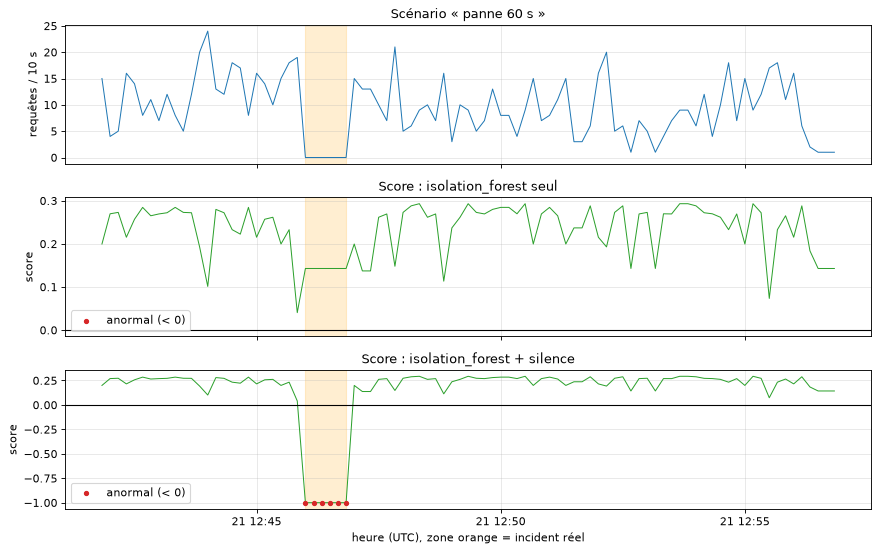

In [5]:
def tracer(nom_scenario, nom_modele):
    inc, fenetre = incidents[nom_scenario]
    temps = pd.to_datetime(inc.index, unit="s", utc=True)
    t0, t1 = temps[inc.index.get_loc(fenetre[0])], temps[inc.index.get_loc(fenetre[-1])]
    donnees = inc.drop(columns="_verite")
    fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
    axes[0].plot(temps, inc[FEATURE], lw=0.9)
    axes[0].set(title=f"Scénario « {nom_scenario} »", ylabel="requêtes / 10 s")
    for ax, (etiquette, det) in zip(axes[1:], ((f"{nom_modele} seul", seuls[nom_modele]),
                                               (f"{nom_modele} + silence", avec[nom_modele]))):
        s = det.score(donnees)[COLONNE_SCORE]
        ax.plot(temps, s, lw=0.9, color="tab:green")
        ax.axhline(0, color="black", lw=1)
        anormal = (s < 0).to_numpy()
        ax.scatter(temps[anormal], s.to_numpy()[anormal], color="tab:red", s=14, zorder=3, label="anormal (< 0)")
        ax.set(title=f"Score : {etiquette}", ylabel="score"); ax.legend(loc="lower left")
    for ax in axes:
        ax.axvspan(t0, t1, color="orange", alpha=0.18)
    axes[-1].set_xlabel("heure (UTC), zone orange = incident réel")
    plt.tight_layout(); plt.show()

tracer("panne 60 s", "isolation_forest")

Sans la règle, le score reste **positif** pendant la panne : le modèle trouve la photo normale. Avec la règle, le
score passe à −1 dès la première photo à 0 requête ; l'alerte part à la 3ᵉ photo d'affilée (règle commune à tous).

## 5. Et sur le flood : la règle ne change rien

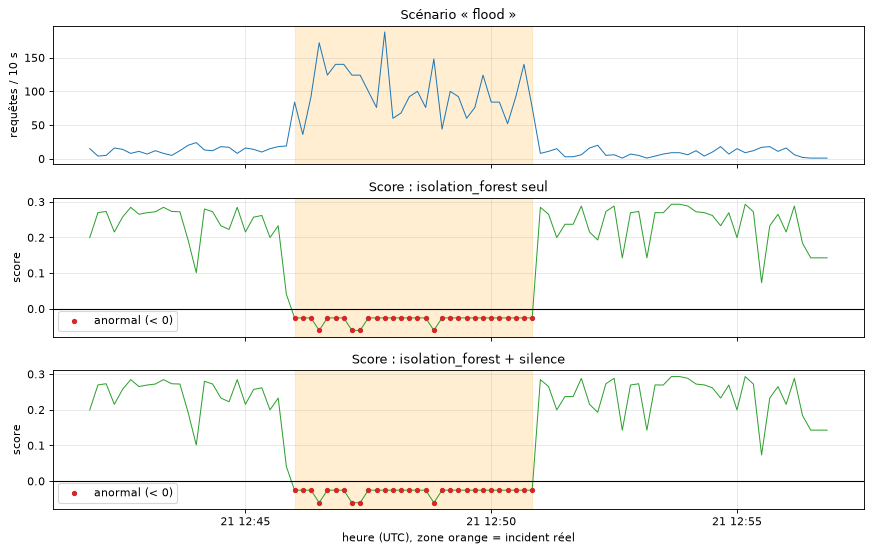

In [6]:
tracer("flood", "isolation_forest")

La règle n'agit que sur les photos silencieuses : les scores d'un incident ordinaire sont **identiques** avec et
sans elle (vérifié ci-dessous).

In [7]:
identiques = {nom: avec[nom].score(test.copy()).equals(seuls[nom].score(test.copy())) for nom in NOMS}
inc_flood = incidents["flood"][0].drop(columns="_verite")
identiques_flood = {nom: avec[nom].score(inc_flood).equals(seuls[nom].score(inc_flood)) for nom in NOMS}
pd.DataFrame({"trafic normal": identiques, "flood": identiques_flood}).rename_axis("scores identiques ?")

,trafic normal,flood
scores identiques ?,,
isolation_forest,True,True
lof,True,True
statistique,True,True


## 6. Bilan : délai de détection par scénario

In [8]:
def libelle(r):
    if r["type"] != "detecte":
        return "non détecté"
    return f"{int(r['delai_s'])} s, {r['gravite']}" + ("" if r["nb_fausses_alertes"] == 0 else " (fausse alerte !)")

lignes = {}
for nom_scenario, (inc, _) in incidents.items():
    bilan = comparer(inc, detecteurs, n_consecutifs=config.N_CONSECUTIFS).set_index("modele")
    lignes[nom_scenario] = bilan.apply(libelle, axis=1)
tableau = pd.DataFrame(lignes)
tableau

,flood,scan,baisse,panne 20 s,panne 30 s,panne 60 s
modele,,,,,,
isolation_forest,"20 s, elevee","40 s, critique",non détecté,non détecté,non détecté,non détecté
isolation_forest + silence,"20 s, elevee","40 s, critique",non détecté,non détecté,"20 s, critique","20 s, critique"
lof,"20 s, elevee","20 s, critique",non détecté,non détecté,non détecté,non détecté
lof + silence,"20 s, elevee","20 s, critique",non détecté,non détecté,"20 s, critique","20 s, critique"
statistique,"20 s, elevee","20 s, critique",non détecté,non détecté,non détecté,non détecté
statistique + silence,"20 s, elevee","20 s, critique",non détecté,non détecté,"20 s, critique","20 s, critique"


**Constats de l'exécution du 21/10** (388 photos, 3402 requêtes du générateur) :

- **Panne 30 s et 60 s** : aucun modèle seul ne les détecte ; avec la règle, les trois les détectent en **20 s** (au
  3ᵉ photo silencieuse), gravité **critique**, bon service.
- **Panne 20 s** : non détectée, avec ou sans règle (2 photos < 3 photos d'affilée exigées).
- **Flood et scan** : résultats identiques avec et sans règle. La règle ne les touche pas.
- **Baisse de trafic** (÷5, jamais à 0) : non détectée, avec ou sans règle. C'est la limite de la règle.

## 7. Fausses alertes : le trafic normal, avec la règle

In [9]:
def evenements(det, donnees):
    tracker = IncidentTracker(det, n_consecutifs=config.N_CONSECUTIFS)
    return [ev for ev in (tracker.mettre_a_jour(donnees.iloc[[i]]) for i in range(len(donnees))) if ev]

complet = df[["timestamp", *mesures]].set_index("timestamp")   # tout normal.csv, y compris le repos
faux = pd.DataFrame({
    "alertes sur le test": {nom: len(evenements(det, test)) for nom, det in detecteurs.items()},
    "alertes sur normal.csv complet": {nom: len(evenements(det, complet)) for nom, det in detecteurs.items()},
})
faux

,alertes sur le test,alertes sur normal.csv complet
isolation_forest,0,0
isolation_forest + silence,0,0
lof,0,0
lof + silence,0,0
statistique,0,0
statistique + silence,0,0


Avec la règle, aucune alerte de plus sur le trafic normal : il n'existe aucune photo à 0 requête dans les données
et le trafic habituel du service reste au-dessus du seuil.

## 8. Ce que la règle ne fait pas (à citer dans le dossier)

- Elle ne détecte **que le zéro** : une baisse de trafic (scénario « baisse ») reste invisible, comme sans elle.
- Elle exige **3 photos d'affilée** : une panne de 20 s n'est pas signalée.
- Une panne de la **collecte des logs** (Loki, relais) ressemble à une panne du service.
- Elle ne s'applique qu'aux services dont la **moyenne apprise** est d'au moins 3 requêtes par photo.
- Elle **complète** les healthchecks Docker et Prometheus (côté infra), elle ne les remplace pas.